In [1]:
!pip install shap

In [2]:
# bibliotecas
import numpy as np
import matplotlib.pyplot as plt
import shap
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC

In [3]:
data = load_breast_cancer() # carrega dataset

In [4]:
X, y = data['data'], data['target'] # X é igual a data e y é igual a target

In [5]:
data['target_names'] # classificação

array(['malignant', 'benign'], dtype='<U9')

In [6]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2) # separa os dados para treino e testes

In [7]:
clf = LinearSVC()
clf.fit(X_train,y_train) # treina o modelo

LinearSVC()

In [8]:
clf.score(X_test,y_test) # score do modelo

0.9649122807017544

In [10]:
clf.predict([X_test[0]]) # predição do modelo

array([0])

In [11]:
explainer = shap.KernelExplainer(clf.predict, shap.kmeans(X_train, 10))

In [13]:
shap_values = explainer.shap_values(X_test) # obtendo os valores do shap

  0%|          | 0/114 [00:00<?, ?it/s]

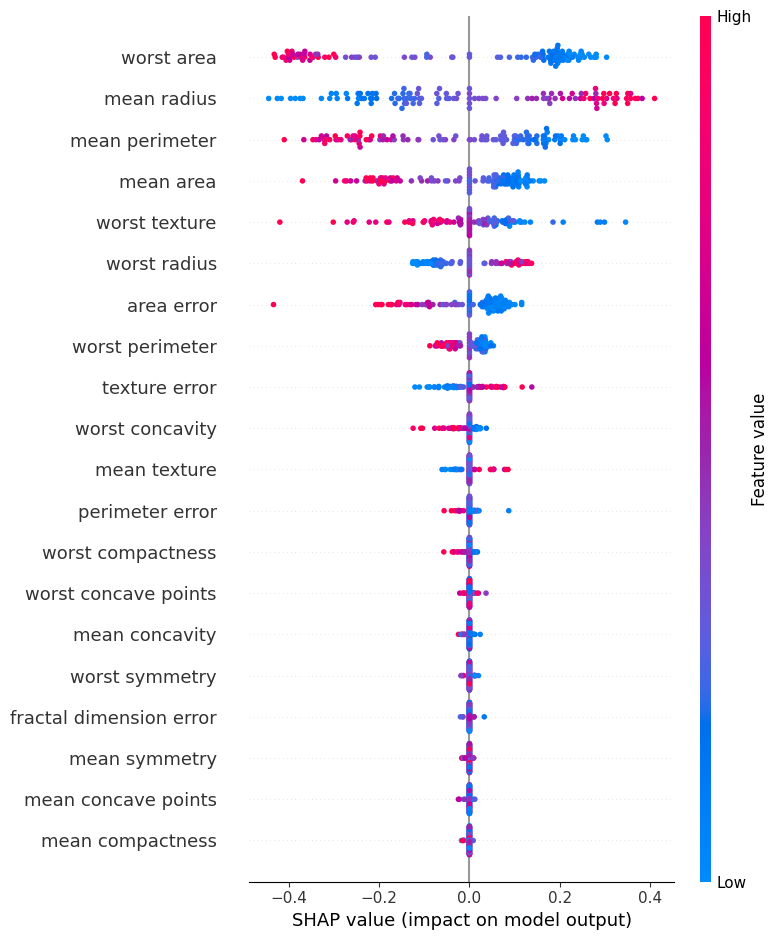

In [16]:
# Identifica quais características têm maior impacto nas previsões do modelo.
# O eixo X representa a intensidade e a direção da influência de cada característica nas previsões.
# O eixo Y apresenta as características organizadas da maior para a menor importância.
shap.summary_plot(shap_values, X_test, feature_names=data['feature_names']) # plotando o shap

In [21]:
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values[5], X_test[5], data['feature_names']) # plotando a Media das predicoes e o quanto cada feature influenciou para o resultado

In [22]:
mean_abs_shap_values = np.abs(shap_values).mean(axis=0) # valores medios

In [23]:
feature_names = data['feature_names']
features_importance = zip(feature_names, mean_abs_shap_values)

In [24]:
sorted_feature_importance = sorted(features_importance, key=lambda x: x[1], reverse=True) # ordena os valores

In [26]:
for feature, importance in sorted_feature_importance:
    print(f"{feature}: {importance}")

worst area: 0.23832910924191175
mean radius: 0.20530041779759656
mean perimeter: 0.17456646138671417
mean area: 0.11192922803574393
worst texture: 0.08042670796838002
worst radius: 0.07482893951835666
area error: 0.07156133154930047
worst perimeter: 0.03203528988967871
texture error: 0.027640876703081314
worst concavity: 0.014622357897014647
mean texture: 0.008674849125626839
perimeter error: 0.0048530324198640335
worst compactness: 0.0033585277674799997
worst concave points: 0.0017274281001253054
mean concavity: 0.001676939027605693
worst symmetry: 0.0013557371388727285
fractal dimension error: 0.000976625539083212
mean symmetry: 0.0008891544555997404
mean concave points: 0.0007990161374942979
mean compactness: 0.0006171369600102676
compactness error: 0.0005884986431564557
mean fractal dimension: 0.0005827442999664713
mean smoothness: 0.0005420779914535989
concavity error: 0.000534287509397373
radius error: 0.0005316650077530974
symmetry error: 0.0004900051051229048
smoothness error: 